In [3]:
import pyodbc

# Nom de votre serveur
server = r"DESKTOP-RRT65BQ\SQLEXPRESS"
database = (
    "TIA"  # Remplacez par le nom de votre base de données
)

try:
  # Connexion avec l'authentification Windows
  conn = pyodbc.connect(
      f"DRIVER={{ODBC Driver 17 for SQL Server}};"
      f"SERVER={server};"
      f"DATABASE={database};"
      f"Trusted_Connection=yes;"
  )
  print("Super ! Connexion à la base de données réussie !")

  # Fermer la connexion
  conn.close()

except Exception as e:
  # Capturer et afficher les informations d'erreur
  print(f"Échec de la connexion. Raison de l'erreur : {e}")

Super ! Connexion à la base de données réussie !


In [8]:

import pyodbc
import pandas as pd

# =====================================
# 1. Connect to AdventureWorks2025
# =====================================

server = r"DESKTOP-RRT65BQ\SQLEXPRESS"
database = "AdventureWorks2025"

conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
)

print("Successfully connected to:", database)

# =====================================
# 2. Extract all tables
# =====================================

cursor = conn.cursor()

cursor.execute("""
SELECT
    s.name AS SchemaName,
    t.name AS TableName,
    SUM(p.rows) AS TotalRows
FROM sys.tables AS t
INNER JOIN sys.schemas AS s
    ON t.schema_id = s.schema_id
INNER JOIN sys.partitions AS p
    ON t.object_id = p.object_id
WHERE p.index_id IN (0, 1)
GROUP BY
    s.name,
    t.name
ORDER BY
    s.name,
    t.name;
""")

tables = pd.DataFrame.from_records(
    cursor.fetchall(),
    columns=[col[0] for col in cursor.description]
)

print("\n========== ALL TABLES ==========")
print(tables.to_string(index=False))

print("\nTotal number of tables:", len(tables))

# =====================================
# 3. Extract all columns
# =====================================

cursor.execute("""
SELECT
    s.name AS SchemaName,
    t.name AS TableName,
    c.name AS ColumnName,
    ty.name AS DataType,
    c.max_length AS MaxLength,
    c.is_nullable AS IsNullable
FROM sys.tables AS t
INNER JOIN sys.schemas AS s
    ON t.schema_id = s.schema_id
INNER JOIN sys.columns AS c
    ON t.object_id = c.object_id
INNER JOIN sys.types AS ty
    ON c.user_type_id = ty.user_type_id
ORDER BY
    s.name,
    t.name,
    c.column_id;
""")

columns = pd.DataFrame.from_records(
    cursor.fetchall(),
    columns=[col[0] for col in cursor.description]
)

print("\n========== ALL COLUMNS ==========")
print(columns.to_string(index=False))

# =====================================
# 4. Save metadata
# =====================================

tables.to_csv(
    "database_tables.csv",
    index=False,
    encoding="utf-8-sig"
)

columns.to_csv(
    "database_columns.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nMetadata extraction completed!")



Successfully connected to: AdventureWorks2025

========== ALL TABLES ==========
    SchemaName                             TableName  TotalRows
           dbo                        AWBuildVersion          1
           dbo                           DatabaseLog        927
           dbo                              ErrorLog          0
HumanResources                            Department         16
HumanResources                              Employee        290
HumanResources             EmployeeDepartmentHistory        296
HumanResources                    EmployeePayHistory        316
HumanResources                          JobCandidate         13
HumanResources                                 Shift          3
        Person                               Address      19614
        Person                           AddressType          6
        Person                        BusinessEntity      20777
        Person                 BusinessEntityAddress      19614
        Person          

In [9]:
import pyodbc
import pandas as pd

# 1. Connect to AdventureWorks2025
conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=DESKTOP-RRT65BQ\\SQLEXPRESS;"
    "DATABASE=AdventureWorks2025;"
    "Trusted_Connection=yes;"
)

# 2. Check order status distribution
query_status = """
SELECT
    Status,
    COUNT(*) AS NumberOfOrders
FROM Sales.SalesOrderHeader
GROUP BY Status
ORDER BY Status;
"""

cursor = conn.cursor()
cursor.execute(query_status)

status_data = cursor.fetchall()

df_status = pd.DataFrame.from_records(
    status_data,
    columns=["Status", "NumberOfOrders"]
)

print("Order Status Distribution:")
display(df_status)

Order Status Distribution:


,Status,NumberOfOrders
0,5,31465


In [10]:
# Extract Customer table
query_customer = """
SELECT *
FROM Sales.Customer;
"""

cursor.execute(query_customer)

customer_data = cursor.fetchall()

df_customer = pd.DataFrame.from_records(
    customer_data,
    columns=[column[0] for column in cursor.description]
)

# Extract SalesOrderHeader table
query_orders = """
SELECT *
FROM Sales.SalesOrderHeader;
"""

cursor.execute(query_orders)

order_data = cursor.fetchall()

df_orders = pd.DataFrame.from_records(
    order_data,
    columns=[column[0] for column in cursor.description]
)

# Basic information
print("Customer dataset:", df_customer.shape)
print("Order dataset:", df_orders.shape)

# Missing values
print("\nCustomer missing values:")
display(df_customer.isnull().sum())

print("\nOrder missing values:")
display(df_orders.isnull().sum())

# Duplicate records
print("\nCustomer duplicate rows:", df_customer.duplicated().sum())
print("Order duplicate rows:", df_orders.duplicated().sum())

Customer dataset: (19820, 7)
Order dataset: (31465, 26)

Customer missing values:


CustomerID           0
PersonID           701
StoreID          18484
TerritoryID          0
AccountNumber        0
rowguid              0
ModifiedDate         0
dtype: int64


Order missing values:


SalesOrderID                  0
RevisionNumber                0
OrderDate                     0
DueDate                       0
ShipDate                      0
Status                        0
OnlineOrderFlag               0
SalesOrderNumber              0
PurchaseOrderNumber       27659
AccountNumber                 0
CustomerID                    0
SalesPersonID             27659
TerritoryID                   0
BillToAddressID               0
ShipToAddressID               0
ShipMethodID                  0
CreditCardID               1131
CreditCardApprovalCode     1131
CurrencyRateID            17489
SubTotal                      0
TaxAmt                        0
Freight                       0
TotalDue                      0
Comment                   31465
rowguid                       0
ModifiedDate                  0
dtype: int64


Customer duplicate rows: 0
Order duplicate rows: 0


In [11]:
# 1. Convert OrderDate to datetime
df_orders["OrderDate"] = pd.to_datetime(df_orders["OrderDate"])

# 2. Define the reference date
reference_date = df_orders["OrderDate"].max() + pd.Timedelta(days=1)

# 3. Calculate RFM features
df_rfm = df_orders.groupby("CustomerID").agg(
    Recency=("OrderDate", lambda x: (reference_date - x.max()).days),
    Frequency=("SalesOrderID", "count"),
    Monetary=("TotalDue", "sum"),
    AverageOrderValue=("TotalDue", "mean")
).reset_index()

# 4. Add customer territory information
df_rfm = df_rfm.merge(
    df_customer[["CustomerID", "TerritoryID"]],
    on="CustomerID",
    how="left"
)

# 5. Inspect the new dataset
print("RFM dataset shape:", df_rfm.shape)

print("\nFirst 5 rows:")
display(df_rfm.head())

print("\nMissing values:")
display(df_rfm.isnull().sum())

print("\nDescriptive statistics:")
display(df_rfm.describe())

RFM dataset shape: (19119, 6)

First 5 rows:


,CustomerID,Recency,Frequency,Monetary,AverageOrderValue,TerritoryID
0,11000,271,3,9115.1341,3038.378033,9
1,11001,50,3,7054.1875,2351.395833,9
2,11002,340,3,8966.0143,2988.671433,9
3,11003,264,3,8993.9155,2997.971833,9
4,11004,273,3,9056.5911,3018.8637,9



Missing values:


CustomerID           0
Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
TerritoryID          0
dtype: int64


Descriptive statistics:


,CustomerID,Recency,Frequency,TerritoryID
count,19119.000000,19119.000000,19119.000000,19119.000000
mean,20559.000000,191.267483,1.645745,5.861447
std,5519.324234,150.423605,1.457054,3.052612
min,11000.000000,1.000000,1.000000,1.000000
25%,15779.500000,86.000000,1.000000,4.000000
50%,20559.000000,166.000000,1.000000,6.000000
75%,25338.500000,264.000000,2.000000,9.000000
max,30118.000000,1127.000000,28.000000,10.000000


In [12]:
# 1. Check data types
print("Data types:")
display(df_rfm.dtypes)

# 2. Check missing values
print("\nMissing values:")
display(df_rfm.isnull().sum())

# 3. Descriptive statistics
print("\nDescriptive statistics:")
display(df_rfm.describe())

# 4. Check unique customers
print("\nNumber of unique customers:")
print(df_rfm["CustomerID"].nunique())

# 5. Check negative and zero values
print("\nNon-positive values:")

for col in ["Recency", "Frequency", "Monetary", "AverageOrderValue"]:
    print(col, ":", (df_rfm[col] <= 0).sum())

Data types:


CustomerID            int64
Recency               int64
Frequency             int64
Monetary             object
AverageOrderValue    object
TerritoryID           int64
dtype: object


Missing values:


CustomerID           0
Recency              0
Frequency            0
Monetary             0
AverageOrderValue    0
TerritoryID          0
dtype: int64


Descriptive statistics:


,CustomerID,Recency,Frequency,TerritoryID
count,19119.000000,19119.000000,19119.000000,19119.000000
mean,20559.000000,191.267483,1.645745,5.861447
std,5519.324234,150.423605,1.457054,3.052612
min,11000.000000,1.000000,1.000000,1.000000
25%,15779.500000,86.000000,1.000000,4.000000
50%,20559.000000,166.000000,1.000000,6.000000
75%,25338.500000,264.000000,2.000000,9.000000
max,30118.000000,1127.000000,28.000000,10.000000



Number of unique customers:
19119

Non-positive values:
Recency : 0
Frequency : 0
Monetary : 0
AverageOrderValue : 0


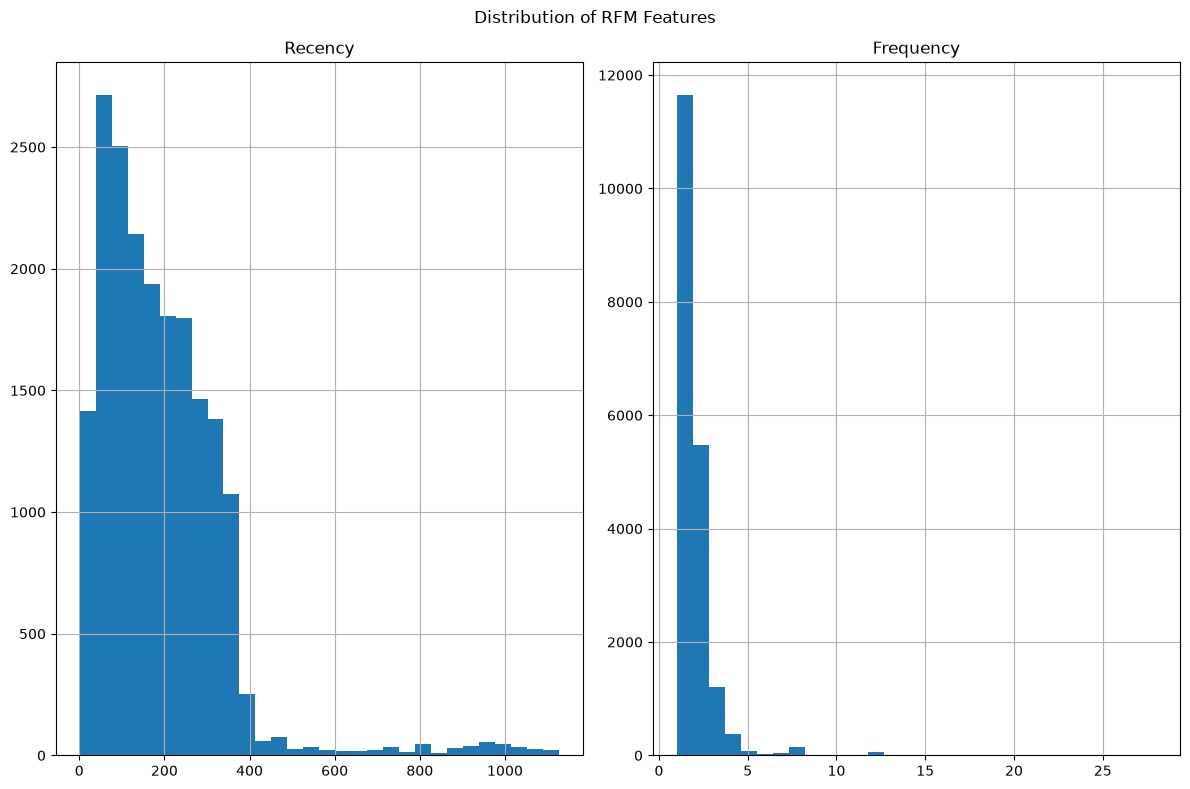

In [13]:
import matplotlib.pyplot as plt

features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue"
]

df_rfm[features].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution of RFM Features")
plt.tight_layout()
plt.show()

In [14]:
# Convert monetary variables to numeric types
df_rfm["Monetary"] = pd.to_numeric(df_rfm["Monetary"])

df_rfm["AverageOrderValue"] = pd.to_numeric(
    df_rfm["AverageOrderValue"]
)

# Select numerical clustering features
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue"
]

df_cluster = df_rfm[features].copy()

# Check data types
print("Data types:")
display(df_cluster.dtypes)

# Check descriptive statistics
print("\nDescriptive statistics:")
display(df_cluster.describe())

Data types:


Recency                int64
Frequency              int64
Monetary             float64
AverageOrderValue    float64
dtype: object


Descriptive statistics:


,Recency,Frequency,Monetary,AverageOrderValue
count,19119.000000,19119.000000,19119.000000,19119.000000
mean,191.267483,1.645745,6444.729647,1678.117828
std,150.423605,1.457054,43756.276004,6034.784983
min,1.000000,1.000000,1.518300,1.518300
25%,86.000000,1.000000,60.752900,45.829900
50%,166.000000,1.000000,606.622900,606.622900
75%,264.000000,2.000000,3119.149400,2152.834250
max,1127.000000,28.000000,989184.082000,151704.902175


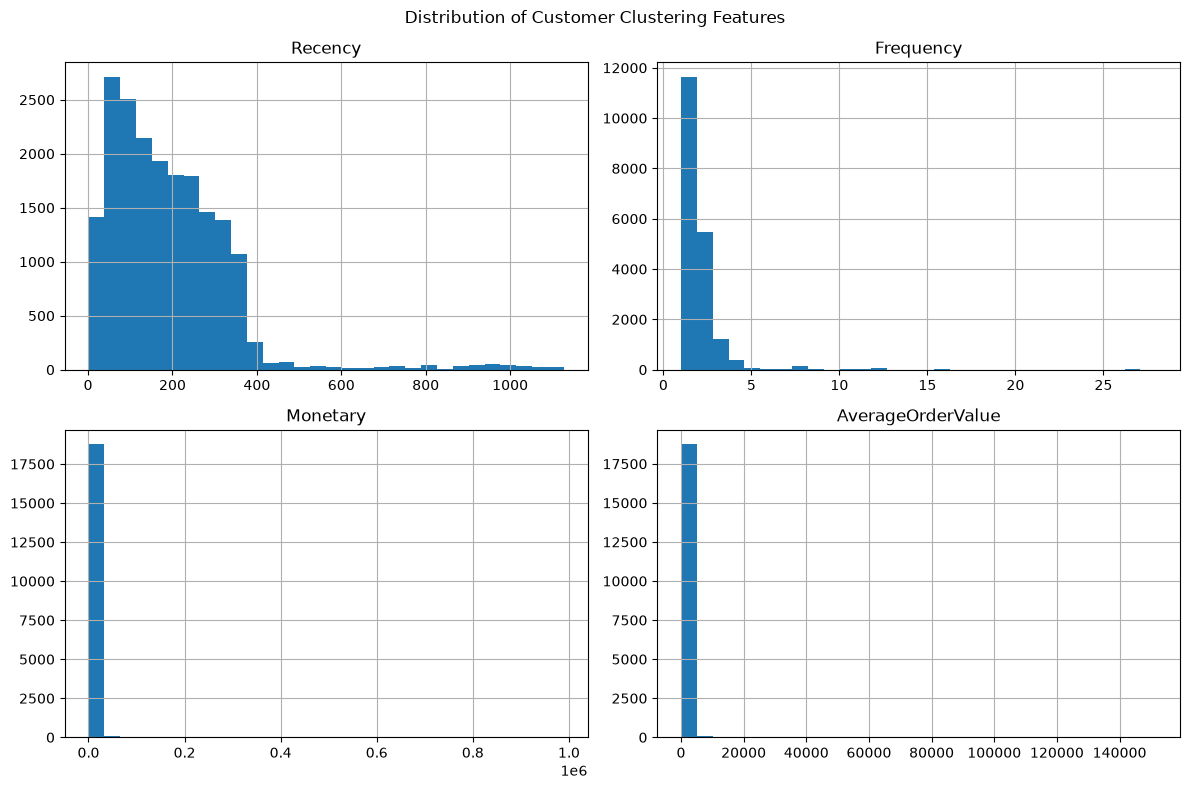

In [15]:
import matplotlib.pyplot as plt

df_cluster.hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution of Customer Clustering Features")
plt.tight_layout()
plt.show()

In [16]:
print("Skewness:")
display(df_cluster.skew())

Skewness:


Recency               2.435350
Frequency             7.388770
Monetary             12.797698
AverageOrderValue    10.846958
dtype: float64

In [17]:
for col in features:

    Q1 = df_cluster[col].quantile(0.25)
    Q3 = df_cluster[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_cluster[
        (df_cluster[col] < lower_bound) |
        (df_cluster[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of outliers:", len(outliers))


Recency
Lower bound: -181.0
Upper bound: 531.0
Number of outliers: 465

Frequency
Lower bound: -0.5
Upper bound: 3.5
Number of outliers: 793

Monetary
Lower bound: -4526.84185
Upper bound: 7706.74415
Number of outliers: 839

AverageOrderValue
Lower bound: -3114.6766249999996
Upper bound: 5313.340775
Number of outliers: 364


Skewness after Log Transformation:


Recency             -1.063682
Frequency            2.197602
Monetary             0.140627
AverageOrderValue   -0.046275
dtype: float64

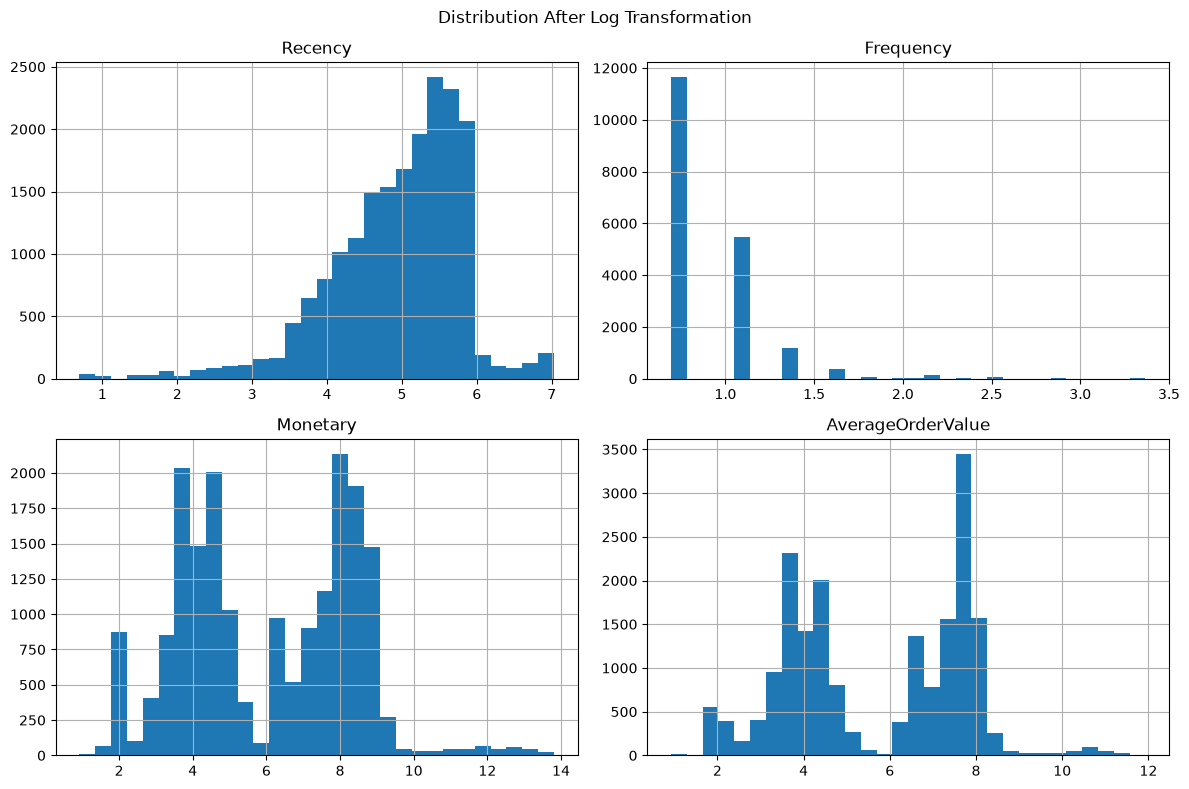

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Apply Log Transformation
df_cluster_log = np.log1p(df_cluster)

# Check skewness after transformation
print("Skewness after Log Transformation:")
display(df_cluster_log.skew())

# Visualize distributions after transformation
df_cluster_log.hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution After Log Transformation")
plt.tight_layout()
plt.show()

In [19]:
skewness_comparison = pd.DataFrame({
    "Before Log": df_cluster.skew(),
    "After Log": df_cluster_log.skew()
})

display(skewness_comparison)

,Before Log,After Log
Recency,2.435350,-1.063682
Frequency,7.388770,2.197602
Monetary,12.797698,0.140627
AverageOrderValue,10.846958,-0.046275


In [20]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Standardize the transformed features
df_cluster_scaled = pd.DataFrame(
    scaler.fit_transform(df_cluster_log),
    columns=df_cluster_log.columns,
    index=df_cluster_log.index
)

# Check standardized data
print("Standardized data:")
display(df_cluster_scaled.head())

print("\nMean:")
display(df_cluster_scaled.mean())

print("\nStandard deviation:")
display(df_cluster_scaled.std())

Standardized data:


,Recency,Frequency,Monetary,AverageOrderValue
0,0.744496,1.49733,1.331341,1.128007
1,-1.164131,1.49733,1.220409,1.003269
2,1.002268,1.49733,1.324202,1.119979
3,0.714769,1.49733,1.325547,1.121491
4,0.752849,1.49733,1.328552,1.124871



Mean:


Recency             -3.805616e-16
Frequency           -2.616361e-16
Monetary             2.586630e-16
AverageOrderValue   -2.423107e-16
dtype: float64


Standard deviation:


Recency              1.000026
Frequency            1.000026
Monetary             1.000026
AverageOrderValue    1.000026
dtype: float64

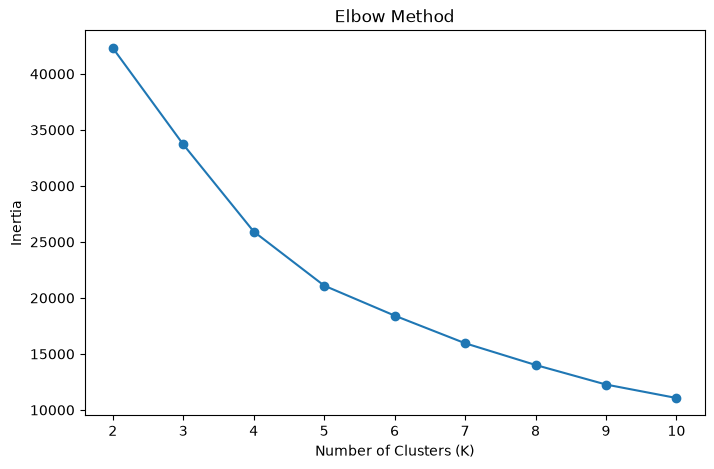

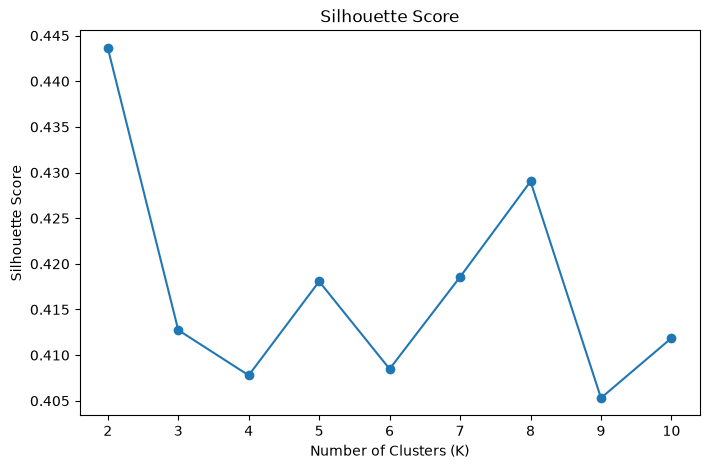

,K,Inertia,Silhouette Score
0,2,42310.142290,0.443643
1,3,33701.002092,0.412746
2,4,25926.331197,0.407785
3,5,21100.482229,0.418073
4,6,18423.432314,0.408483
5,7,15958.276911,0.418560
6,8,14017.531239,0.429026
7,9,12271.010345,0.405304
8,10,11069.063326,0.411866


In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(df_cluster_scaled)

    inertia.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(df_cluster_scaled, labels)
    )

# Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(K_range)
plt.show()

# Silhouette Score
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.xticks(K_range)
plt.show()

# Display results
results = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertia,
    "Silhouette Score": silhouette_scores
})

display(results)

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [2, 4, 8]

comparison = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(df_cluster_scaled)

    score = silhouette_score(
        df_cluster_scaled,
        labels
    )

    sizes = pd.Series(labels).value_counts().sort_index()

    comparison.append({
        "K": k,
        "Silhouette Score": score,
        "Cluster Sizes": sizes.to_dict()
    })

display(pd.DataFrame(comparison))

,K,Silhouette Score,Cluster Sizes
0,2,0.443643,"{0: 9837, 1: 9282}"
1,4,0.407785,"{0: 6946, 1: 8142, 2: 1619, 3: 2412}"
2,8,0.429026,"{0: 2080, 1: 1789, 2: 6163, 3: 2384, 4: 3101, ..."


In [23]:
from sklearn.cluster import KMeans

k_values = [2, 4, 8]

cluster_profiles = {}

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(df_cluster_scaled)

    # Combine original features with cluster labels
    df_result = df_cluster.copy()
    df_result["Cluster"] = labels

    # Calculate cluster sizes
    cluster_sizes = df_result["Cluster"].value_counts().sort_index()

    # Calculate average customer characteristics
    profile = df_result.groupby("Cluster")[features].mean()

    # Add number of customers
    profile.insert(0, "NumberOfCustomers", cluster_sizes)

    cluster_profiles[k] = profile

    print(f"\n========== K = {k} ==========")
    display(profile.round(2))


========== K = 2 ==========


,NumberOfCustomers,Recency,Frequency,Monetary,AverageOrderValue
Cluster,,,,,
0,9837,209.47,2.03,12460.37,3208.95
1,9282,171.97,1.24,69.39,55.75



========== K = 4 ==========


,NumberOfCustomers,Recency,Frequency,Monetary,AverageOrderValue
Cluster,,,,,
0,6946,215.88,1.14,62.79,55.32
1,8142,222.86,1.50,3016.26,1938.55
2,1619,150.29,4.72,60506.64,9716.71
3,2412,41.26,1.53,108.60,76.53



========== K = 8 ==========


,NumberOfCustomers,Recency,Frequency,Monetary,AverageOrderValue
Cluster,,,,,
0,2080,79.08,2.36,5153.37,2147.67
1,1789,89.84,1.00,1521.80,1521.80
2,6163,217.62,1.00,54.97,54.97
3,2384,380.07,1.00,1824.32,1824.32
4,3101,249.98,2.19,6742.25,2697.48
5,1716,31.86,1.29,72.20,55.07
6,1431,140.47,2.34,138.41,58.30
7,455,117.56,8.48,184302.53,25634.17


Feature Correlation Matrix:


,Recency,Frequency,Monetary,AverageOrderValue
Recency,1.000,-0.170,0.078,0.127
Frequency,-0.170,1.000,0.587,0.426
Monetary,0.078,0.587,1.000,0.982
AverageOrderValue,0.127,0.426,0.982,1.000


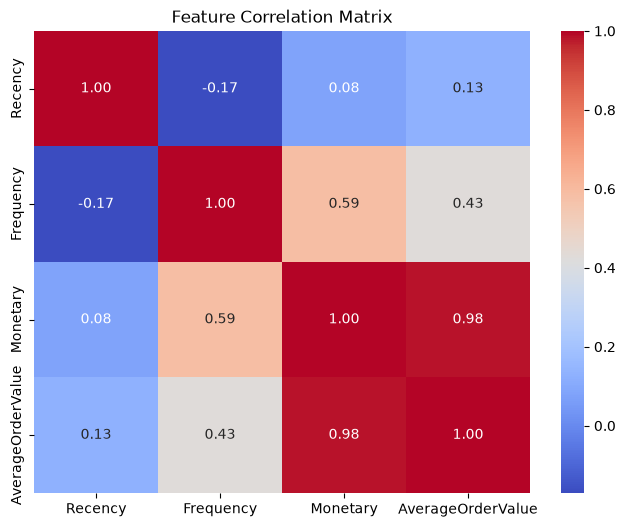

In [24]:
# Calculate feature correlations
correlation_matrix = df_cluster_log.corr()

print("Feature Correlation Matrix:")
display(correlation_matrix.round(3))

# Visualize correlation matrix
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()

In [25]:
from sklearn.preprocessing import StandardScaler

# Select three RFM features
features_rfm = [
    "Recency",
    "Frequency",
    "Monetary"
]

# Remove AverageOrderValue
df_rfm_selected = df_cluster_log[features_rfm].copy()

# Standardize the selected features
scaler_rfm = StandardScaler()

df_rfm_scaled = pd.DataFrame(
    scaler_rfm.fit_transform(df_rfm_selected),
    columns=features_rfm,
    index=df_rfm_selected.index
)

# Check results
print("Mean:")
display(df_rfm_scaled.mean())

print("Standard deviation:")
display(df_rfm_scaled.std())

Mean:


Recency     -3.805616e-16
Frequency   -2.616361e-16
Monetary     2.586630e-16
dtype: float64

Standard deviation:


Recency      1.000026
Frequency    1.000026
Monetary     1.000026
dtype: float64

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_rfm = []
silhouette_rfm = []

K_range = range(2, 11)

for k in K_range:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(df_rfm_scaled)

    inertia_rfm.append(model.inertia_)

    silhouette_rfm.append(
        silhouette_score(df_rfm_scaled, labels)
    )

# Display results
results_rfm = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertia_rfm,
    "Silhouette Score": silhouette_rfm
})

display(results_rfm)

,K,Inertia,Silhouette Score
0,2,36797.868997,0.389682
1,3,27290.232526,0.375743
2,4,22023.239218,0.356996
3,5,17586.073865,0.397243
4,6,15213.467029,0.395648
5,7,13105.921584,0.389682
6,8,11279.536920,0.405312
7,9,9657.194145,0.437424
8,10,8818.789985,0.444041


In [28]:
from sklearn.cluster import KMeans
import pandas as pd

# Train the final K-Means model
final_kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

# Assign cluster labels
cluster_labels = final_kmeans.fit_predict(df_rfm_scaled)

# Add cluster labels to the original RFM dataset
df_final = df_rfm.loc[df_rfm_scaled.index].copy()
df_final["Cluster"] = cluster_labels

# Display the first rows
display(df_final.head())

# Display cluster sizes
print("Number of customers in each cluster:")
display(
    df_final["Cluster"]
    .value_counts()
    .sort_index()
)

,CustomerID,Recency,Frequency,Monetary,AverageOrderValue,TerritoryID,Cluster
0,11000,271,3,9115.1341,3038.378033,9,9
1,11001,50,3,7054.1875,2351.395833,9,0
2,11002,340,3,8966.0143,2988.671433,9,9
3,11003,264,3,8993.9155,2997.971833,9,9
4,11004,273,3,9056.5911,3018.863700,9,9


Number of customers in each cluster:


Cluster
0    1723
1    4793
2    2696
3    1762
4     319
5    2219
6     838
7    2393
8    1418
9     958
Name: count, dtype: int64

In [29]:
# Calculate customer profiles using original values
cluster_profile = df_final.groupby("Cluster").agg(
    NumberOfCustomers=("CustomerID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean")
).round(2)

display(cluster_profile)

,NumberOfCustomers,AvgRecency,AvgFrequency,AvgMonetary
Cluster,,,,
0,1723,71.73,2.22,4471.35
1,4793,250.62,1.00,55.37
2,2696,243.06,2.00,4417.64
3,1762,89.52,1.00,1542.86
4,319,106.52,10.19,202826.68
5,2219,81.68,1.00,54.08
6,838,15.30,1.57,90.40
7,2393,379.27,1.00,1817.72
8,1418,140.40,2.25,128.71


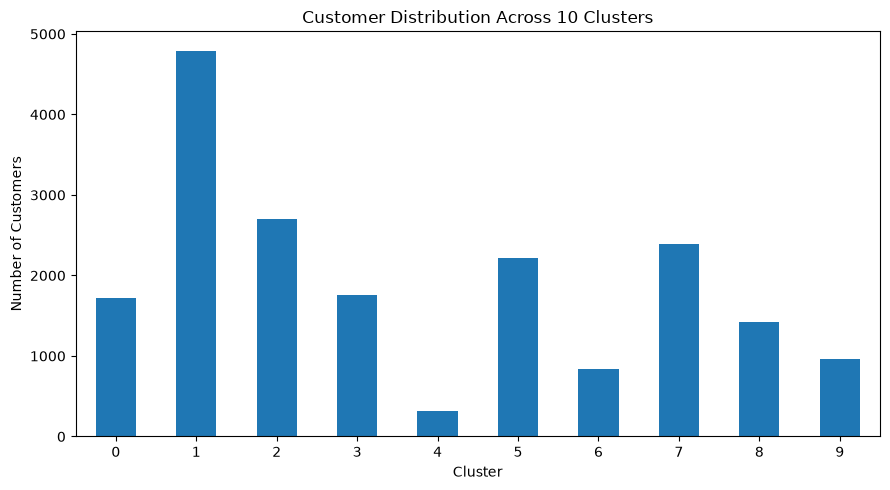

In [30]:
import matplotlib.pyplot as plt

cluster_sizes = df_final["Cluster"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

cluster_sizes.plot(kind="bar")

plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("Customer Distribution Across 10 Clusters")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
from sklearn.metrics import silhouette_score

final_score = silhouette_score(
    df_rfm_scaled,
    cluster_labels
)

print("Final K-Means Silhouette Score:", round(final_score, 4))

Final K-Means Silhouette Score: 0.444


Résultats de la segmentation des clients avec K-Means
- 19 119 clients répartis en 10 clusters.
- Score Silhouette final : 0,4441.
- Identification de différents profils de consommation.
- Le cluster 4 représente les clients VIP, avec une dépense moyenne particulièrement élevée.
- Le cluster 9 regroupe des clients à forte valeur et à fréquence d'achat élevée.
- Le cluster 1 représente le groupe le plus nombreux, caractérisé par une faible fréquence d'achat et une faible dépense moyenne.
Conclusion :
La méthode K-Means permet d'identifier dix segments de clients ayant des comportements d'achat différents, ce qui peut aider à adapter les stratégies marketing à chaque groupe.

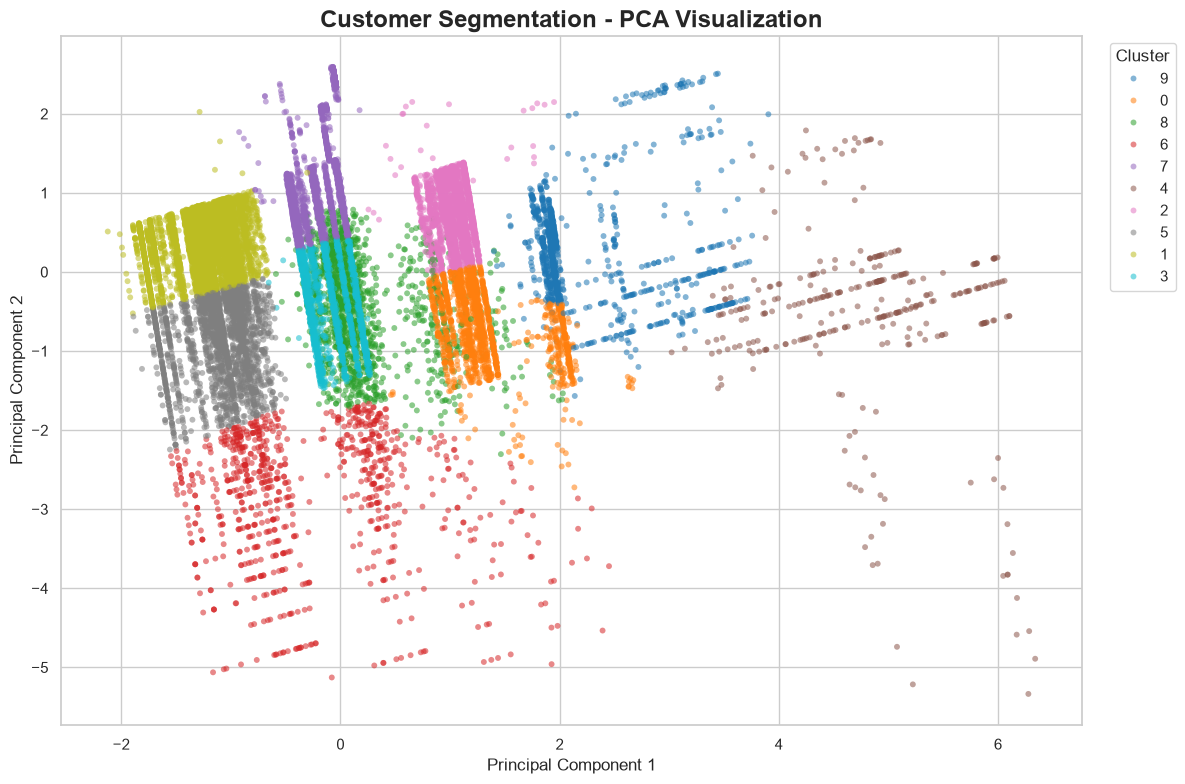

Explained variance: 87.86 %


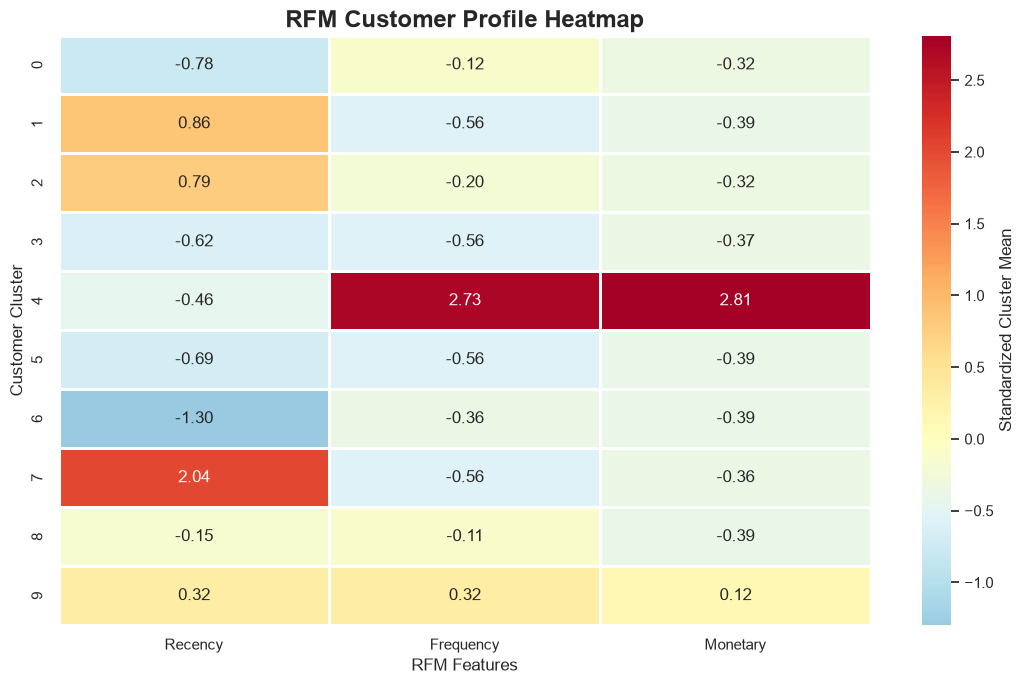

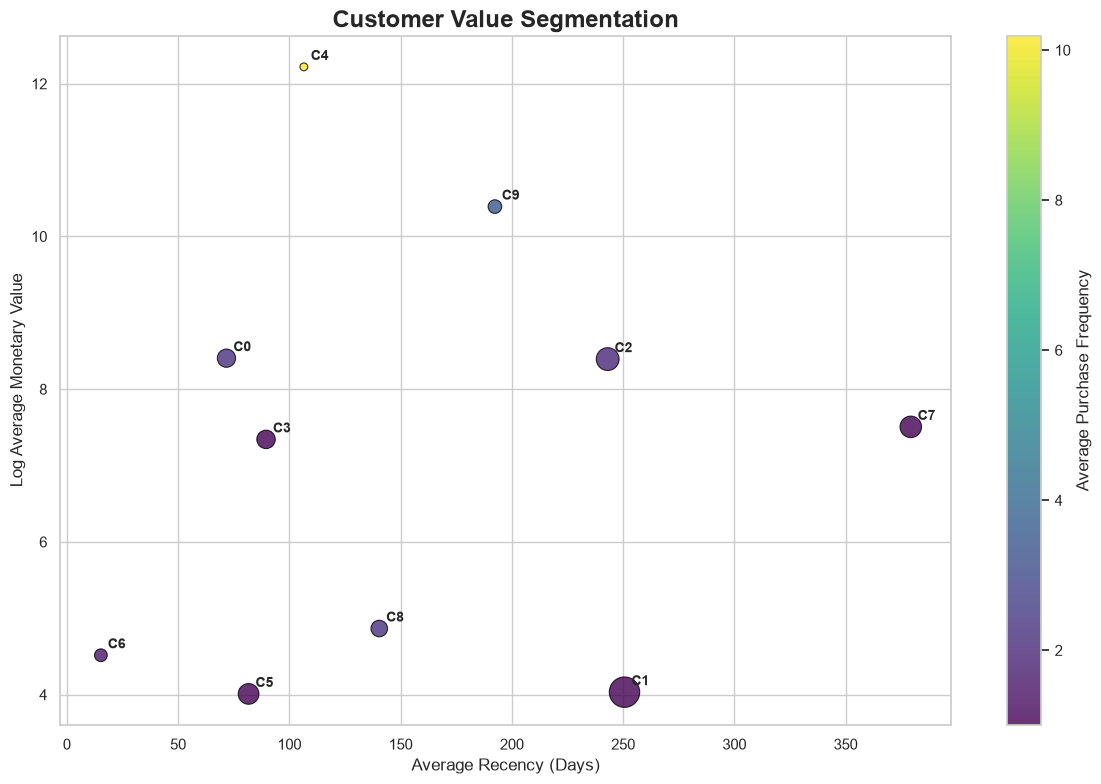

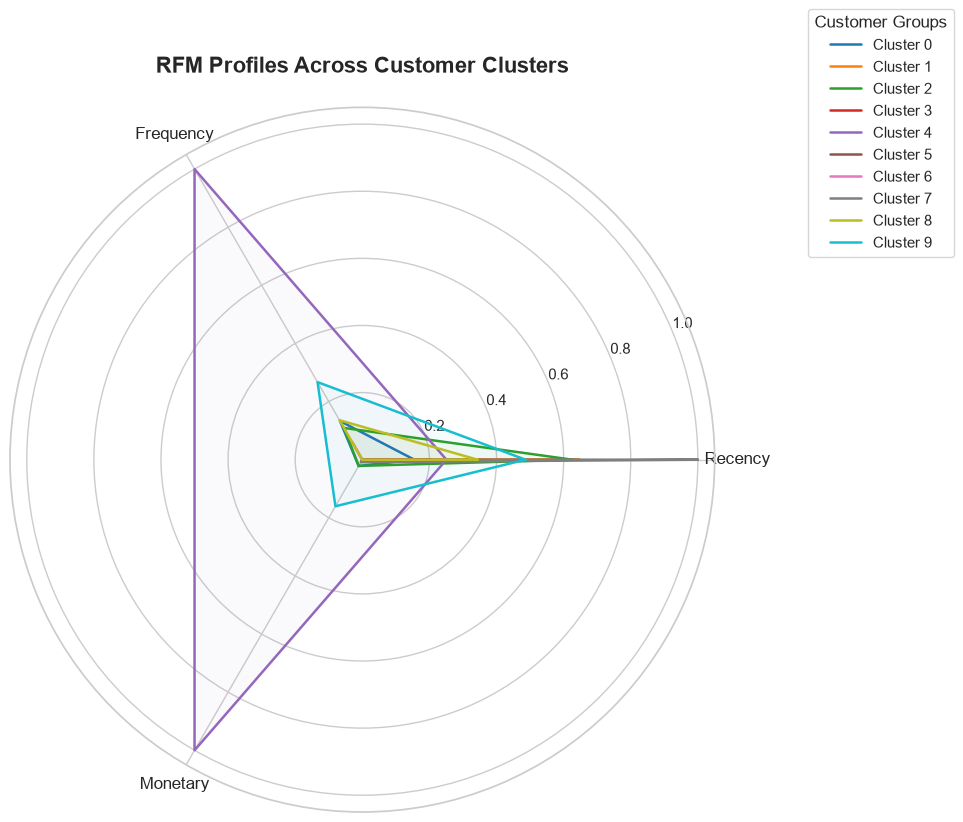

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")

# Reconstruct the dataset safely
plot_data = df_final[
    ["Recency", "Frequency", "Monetary", "Cluster"]
].copy()

# ==========================================
# 1. PCA CLUSTER VISUALIZATION
# ==========================================

pca = PCA(n_components=2)

pca_results = pca.fit_transform(df_rfm_scaled)

pca_df = pd.DataFrame(
    pca_results,
    columns=["PC1", "PC2"],
    index=df_rfm_scaled.index
)

pca_df["Cluster"] = cluster_labels.astype(str)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=18,
    alpha=0.55,
    linewidth=0
)

plt.title(
    "Customer Segmentation - PCA Visualization",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(
    title="Cluster",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

print(
    "Explained variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


# ==========================================
# 2. RFM CLUSTER HEATMAP
# ==========================================

profile = plot_data.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

# Standardize the cluster averages for comparison
profile_z = (
    profile - profile.mean()
) / profile.std()

plt.figure(figsize=(11, 7))

sns.heatmap(
    profile_z,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.8,
    cbar_kws={"label": "Standardized Cluster Mean"}
)

plt.title(
    "RFM Customer Profile Heatmap",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("RFM Features")
plt.ylabel("Customer Cluster")

plt.tight_layout()
plt.show()


# ==========================================
# 3. CUSTOMER VALUE BUBBLE CHART
# ==========================================

bubble_data = plot_data.groupby("Cluster").agg(
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Customers=("Cluster", "size")
).reset_index()

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    bubble_data["Recency"],
    np.log1p(bubble_data["Monetary"]),
    s=bubble_data["Customers"] * 0.10,
    c=bubble_data["Frequency"],
    cmap="viridis",
    alpha=0.8,
    edgecolors="black",
    linewidths=0.8
)

for _, row in bubble_data.iterrows():
    plt.annotate(
        f"C{int(row['Cluster'])}",
        (row["Recency"], np.log1p(row["Monetary"])),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

plt.colorbar(scatter, label="Average Purchase Frequency")

plt.title(
    "Customer Value Segmentation",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Average Recency (Days)")
plt.ylabel("Log Average Monetary Value")

plt.tight_layout()
plt.show()


# ==========================================
# 4. RFM RADAR CHART
# ==========================================

from math import pi

radar_features = ["Recency", "Frequency", "Monetary"]

# Normalize the cluster profiles to 0-1
radar_data = profile.copy()

radar_data = (
    radar_data - radar_data.min()
) / (
    radar_data.max() - radar_data.min()
)

categories = radar_features
N = len(categories)

angles = [
    n / float(N) * 2 * pi
    for n in range(N)
]

angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw={"polar": True}
)

colors = plt.cm.tab10(np.linspace(0, 1, 10))

for i, cluster in enumerate(radar_data.index):

    values = radar_data.loc[cluster].tolist()
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=1.8,
        label=f"Cluster {cluster}",
        color=colors[i]
    )

    ax.fill(
        angles,
        values,
        alpha=0.04,
        color=colors[i]
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)

ax.set_title(
    "RFM Profiles Across Customer Clusters",
    fontsize=16,
    fontweight="bold",
    pad=25
)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.35, 1.15),
    title="Customer Groups"
)

plt.tight_layout()
plt.show()

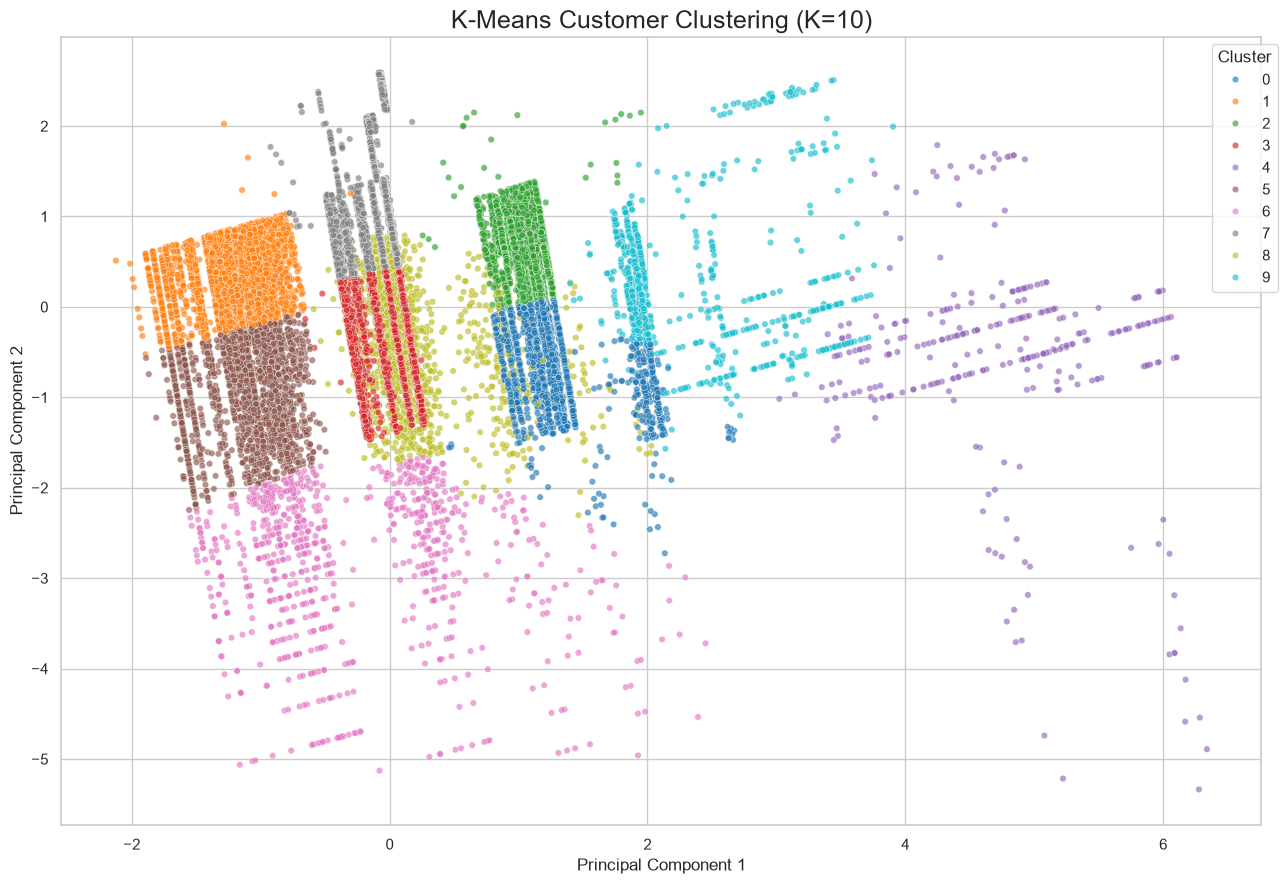

Explained variance: 87.86 %


In [33]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Reduce dimensions to 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df_rfm_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = cluster_labels

plt.figure(figsize=(13, 9))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=22,
    alpha=0.65
)

plt.title("K-Means Customer Clustering (K=10)", fontsize=18)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

print(
    "Explained variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

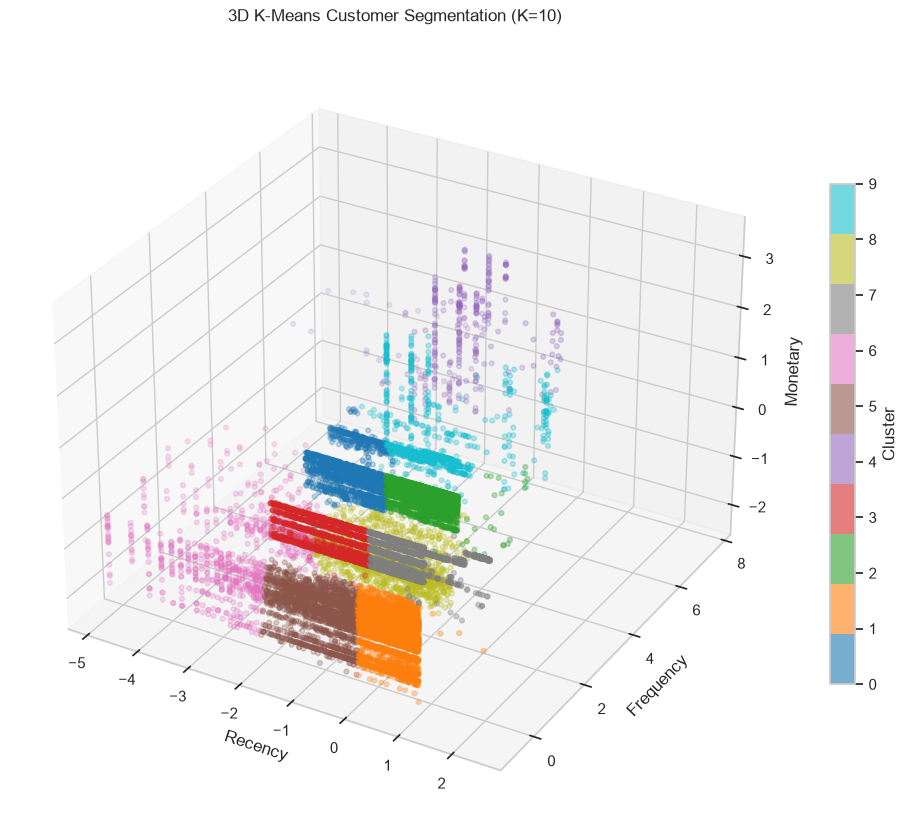

In [34]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(13, 10))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    df_rfm_scaled["Recency"],
    df_rfm_scaled["Frequency"],
    df_rfm_scaled["Monetary"],
    c=cluster_labels,
    cmap="tab10",
    s=12,
    alpha=0.6
)

ax.set_title("3D K-Means Customer Segmentation (K=10)", pad=20)
ax.set_xlabel("Recency")
ax.set_ylabel("Frequency")
ax.set_zlabel("Monetary")

plt.colorbar(scatter, ax=ax, label="Cluster", shrink=0.65)
plt.show()

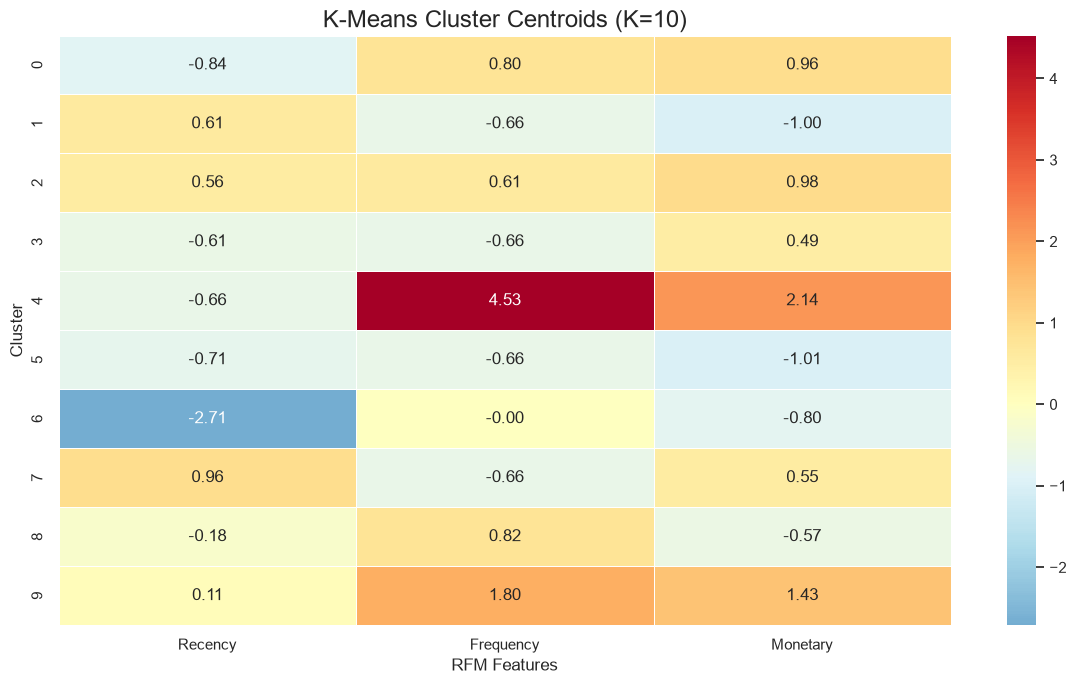

In [35]:
import numpy as np

centers = pd.DataFrame(
    final_kmeans.cluster_centers_,
    columns=["Recency", "Frequency", "Monetary"]
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    centers,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.5
)

plt.title("K-Means Cluster Centroids (K=10)", fontsize=17)
plt.xlabel("RFM Features")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

In [36]:
df_rfm_scaled

,Recency,Frequency,Monetary
0,0.744496,1.497330,1.331341
1,-1.164131,1.497330,1.220409
2,1.002268,1.497330,1.324202
3,0.714769,1.497330,1.325547
4,0.752849,1.497330,1.328552
...,...,...,...
19114,-0.160367,4.017170,1.489468
19115,-0.479143,4.017170,1.372901
19116,-0.160367,2.190714,2.692656
19117,-0.479143,5.159817,3.328567


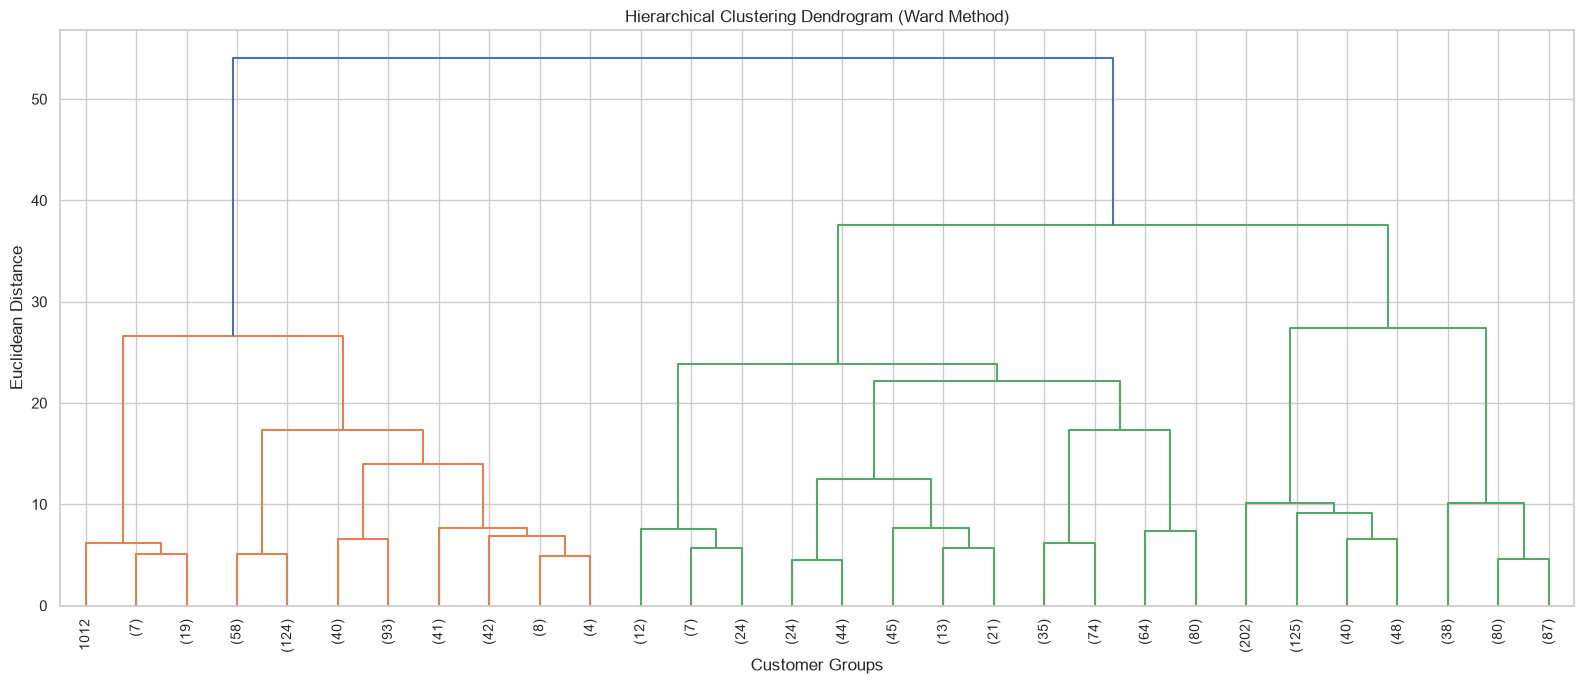

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Random sampling for dendrogram
np.random.seed(42)

sample_indices = np.random.choice(
    len(df_rfm_scaled),
    size=1500,
    replace=False
)

X_sample = df_rfm_scaled.iloc[sample_indices]

# Ward linkage
Z = linkage(X_sample, method='ward')

# Plot dendrogram
plt.figure(figsize=(16, 7))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram (Ward Method)")
plt.xlabel("Customer Groups")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# SQL query: monthly product sales
query = """
SELECT
    DATEFROMPARTS(
        YEAR(h.OrderDate),
        MONTH(h.OrderDate),
        1
    ) AS OrderMonth,
    d.ProductID,
    p.ProductSubcategoryID,
    SUM(d.OrderQty) AS MonthlyQty,
    SUM(d.LineTotal) AS MonthlyRevenue,
    AVG(d.UnitPrice) AS AvgUnitPrice,
    COUNT(DISTINCT h.SalesOrderID) AS OrderCount

FROM Sales.SalesOrderHeader h

INNER JOIN Sales.SalesOrderDetail d
    ON h.SalesOrderID = d.SalesOrderID

INNER JOIN Production.Product p
    ON d.ProductID = p.ProductID

GROUP BY
    YEAR(h.OrderDate),
    MONTH(h.OrderDate),
    d.ProductID,
    p.ProductSubcategoryID

ORDER BY
    OrderMonth,
    d.ProductID;
"""

# Execute query
cursor.execute(query)

columns = [column[0] for column in cursor.description]
df_sales_monthly = pd.DataFrame.from_records(
    cursor.fetchall(),
    columns=columns
)

df_sales_monthly["OrderMonth"] = pd.to_datetime(
    df_sales_monthly["OrderMonth"]
)

print("Dataset shape:", df_sales_monthly.shape)
print("\nFirst rows:")
display(df_sales_monthly.head())

print("\nDate range:")
print(df_sales_monthly["OrderMonth"].min())
print(df_sales_monthly["OrderMonth"].max())

print("\nNumber of products:",
      df_sales_monthly["ProductID"].nunique())

print("\nNumber of months:",
      df_sales_monthly["OrderMonth"].nunique())

Dataset shape: (4012, 7)

First rows:


,OrderMonth,ProductID,ProductSubcategoryID,MonthlyQty,MonthlyRevenue,AvgUnitPrice,OrderCount
0,2022-05-01,707,31,24,484.476000,20.1865,11
1,2022-05-01,708,31,27,545.035500,20.1865,13
2,2022-05-01,709,23,38,216.600000,5.7000,8
3,2022-05-01,710,23,5,28.500000,5.7000,3
4,2022-05-01,711,31,33,666.154500,20.1865,13



Date range:
2022-05-01 00:00:00
2025-06-01 00:00:00

Number of products: 266

Number of months: 38


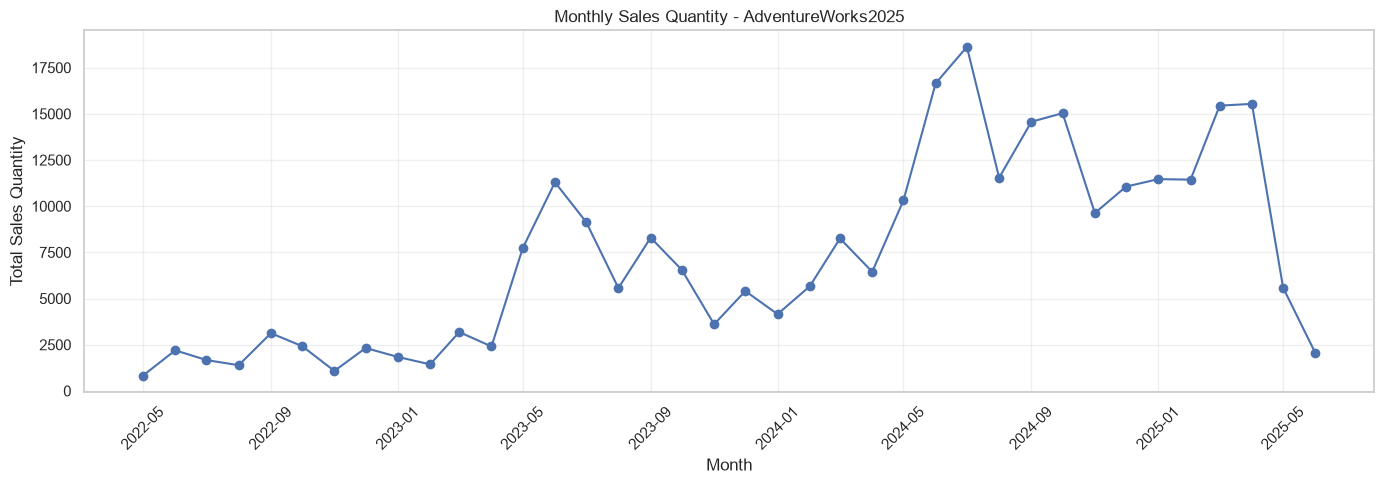

,OrderMonth,MonthlyQty
0,2022-05-01,829
1,2022-06-01,2195
2,2022-07-01,1667
3,2022-08-01,1391
4,2022-09-01,3123


In [39]:
# Monthly total sales quantity
df_monthly_total = (
    df_sales_monthly
    .groupby("OrderMonth")["MonthlyQty"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    df_monthly_total["OrderMonth"],
    df_monthly_total["MonthlyQty"],
    marker="o"
)

plt.title("Monthly Sales Quantity - AdventureWorks2025")
plt.xlabel("Month")
plt.ylabel("Total Sales Quantity")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(df_monthly_total.head())

Sales matrix shape: (38, 266)

Monthly sales quantity:


ProductID,707,708,709,710,711,712,713,714,715,716,...,989,990,991,992,993,994,996,997,998,999
2022-05-01,24.0,27.0,38.0,5.0,33.0,40.0,0.0,16.0,49.0,19.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-06-01,58.0,56.0,134.0,13.0,64.0,103.0,0.0,37.0,114.0,48.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-07-01,55.0,57.0,79.0,6.0,49.0,83.0,0.0,35.0,72.0,40.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-08-01,41.0,29.0,88.0,13.0,26.0,54.0,0.0,30.0,41.0,25.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-09-01,77.0,90.0,123.0,19.0,105.0,136.0,0.0,57.0,126.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Number of products: 266
Number of months: 38
Zero sales ratio: 60.31 %


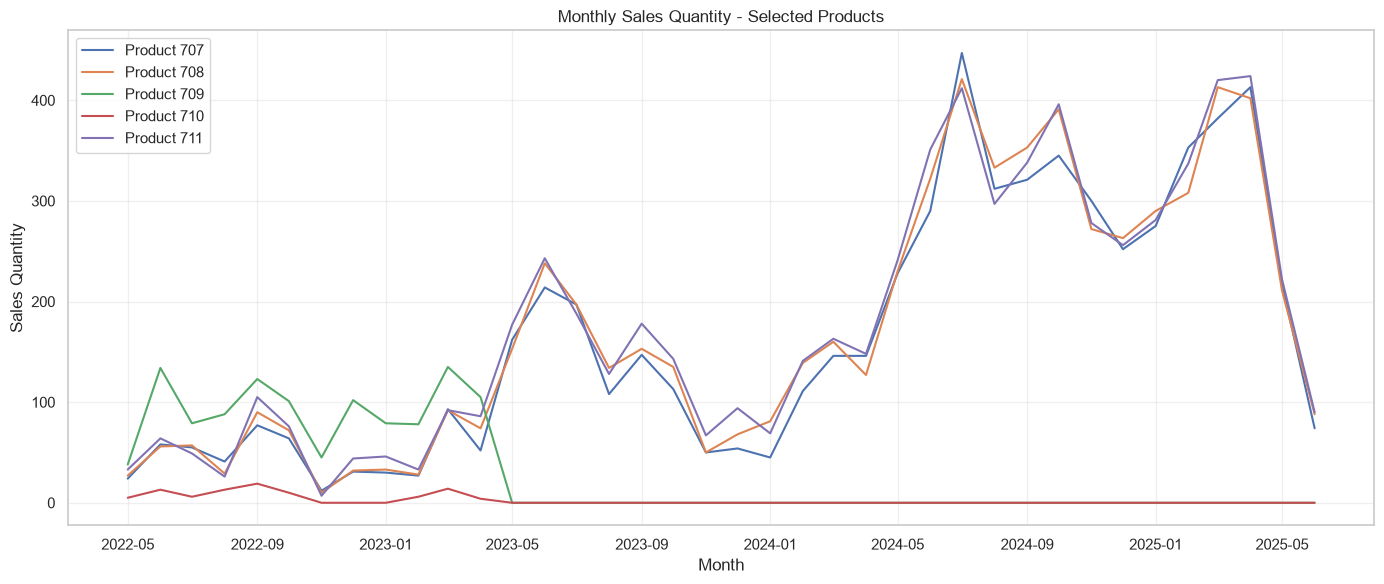

In [40]:
# 1. Create complete monthly date range
all_months = pd.date_range(
    start=df_sales_monthly["OrderMonth"].min(),
    end=df_sales_monthly["OrderMonth"].max(),
    freq="MS"
)

all_products = sorted(df_sales_monthly["ProductID"].unique())

# 2. Create product-month quantity matrix
sales_matrix = (
    df_sales_monthly
    .pivot_table(
        index="OrderMonth",
        columns="ProductID",
        values="MonthlyQty",
        aggfunc="sum"
    )
    .reindex(index=all_months, columns=all_products)
    .fillna(0)
)

print("Sales matrix shape:", sales_matrix.shape)
print("\nMonthly sales quantity:")
display(sales_matrix.head())

# 3. Check zero values
zero_ratio = (sales_matrix == 0).sum().sum() / sales_matrix.size

print("Number of products:", sales_matrix.shape[1])
print("Number of months:", sales_matrix.shape[0])
print("Zero sales ratio:", round(zero_ratio * 100, 2), "%")

# 4. Plot selected products
plt.figure(figsize=(14, 6))

for product_id in all_products[:5]:
    plt.plot(
        sales_matrix.index,
        sales_matrix[product_id],
        label=f"Product {product_id}"
    )

plt.title("Monthly Sales Quantity - Selected Products")
plt.xlabel("Month")
plt.ylabel("Sales Quantity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
query_check = """
SELECT
    MIN(OrderDate) AS FirstOrderDate,
    MAX(OrderDate) AS LastOrderDate,
    COUNT(*) AS TotalOrders
FROM Sales.SalesOrderHeader;
"""

cursor.execute(query_check)
row = cursor.fetchone()

print("First order date:", row[0])
print("Last order date:", row[1])
print("Total orders:", row[2])

First order date: 2022-05-30 00:00:00
Last order date: 2025-06-29 00:00:00
Total orders: 31465


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Parameters
LOOKBACK = 12

# Build sequences for all products
X_list = []
y_list = []
target_months = []

for product_id in sales_matrix.columns:

    values = sales_matrix[product_id].values.astype(float)

    # Log transformation
    values = np.log1p(values)

    for i in range(LOOKBACK, len(values)):

        X_list.append(values[i-LOOKBACK:i])
        y_list.append(values[i])
        target_months.append(i)

X_all = np.array(X_list).reshape(-1, LOOKBACK, 1)
y_all = np.array(y_list).reshape(-1, 1)
target_months = np.array(target_months)

# Chronological split
train_mask = target_months < 30
valid_mask = (target_months >= 30) & (target_months < 34)
test_mask = target_months >= 34

X_train = X_all[train_mask]
X_valid = X_all[valid_mask]
X_test = X_all[test_mask]

y_train = y_all[train_mask]
y_valid = y_all[valid_mask]
y_test = y_all[test_mask]

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)
print("y_test:", y_test.shape)

X_train: (4788, 12, 1)
X_valid: (1064, 12, 1)
X_test: (1064, 12, 1)
y_train: (4788, 1)
y_valid: (1064, 1)
y_test: (1064, 1)


In [43]:
# Fit scalers only on training data
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(
    X_train.reshape(-1, 1)
).reshape(X_train.shape)

X_valid_scaled = scaler_X.transform(
    X_valid.reshape(-1, 1)
).reshape(X_valid.shape)

X_test_scaled = scaler_X.transform(
    X_test.reshape(-1, 1)
).reshape(X_test.shape)

y_train_scaled = scaler_y.fit_transform(y_train)
y_valid_scaled = scaler_y.transform(y_valid)
y_test_scaled = scaler_y.transform(y_test)

print("Preprocessing completed.")

Preprocessing completed.


In [44]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

# Build GRU model
gru_model = Sequential([
    tf.keras.Input(shape=(LOOKBACK, 1)),

    GRU(64, return_sequences=True),
    Dropout(0.2),

    GRU(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

gru_model.summary()

# Callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

# Train
history_gru = gru_model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_valid_scaled, y_valid_scaled),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 12, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,817 (89.13 KB)

 Trainable params: 22,817 (89.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - loss: 0.4450 - mae: 0.5102 - val_loss: 0.1475 - val_mae: 0.2861 - learning_rate: 0.0010
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.2629 - mae: 0.3282 - val_loss: 0.1251 - val_mae: 0.2541 - learning_rate: 0.0010
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.2471 - mae: 0.3077 - val_loss: 0.1269 - val_mae: 0.2568 - learning_rate: 0.0010
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.2445 - mae: 0.3064 - val_loss: 0.1240 - val_mae: 0.2468 - learning_rate: 0.0010
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.2423 - mae: 0.3036 - val_loss: 0.1256 - val_mae: 0.2559 - learning_rate: 0.0010
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.2430 - mae: 0.3041 - val_loss: 0.1213 - val_mae: 0.2418 - learning_rate: 0.0010
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.2391 - mae: 0.3001 - val_loss: 0.1234 - val_mae: 0.2513 - learning_rate: 0.0010
Epoch 

In [46]:
import tensorflow as tf

from tensorflow.keras.layers import (
    Input, Dense, Dropout,
    MultiHeadAttention,
    LayerNormalization,
    GlobalAveragePooling1D,
    Add, Embedding
)
from tensorflow.keras.models import Model

def build_transformer():

    inputs = Input(shape=(LOOKBACK, 1))

    # Project input features
    x = Dense(32)(inputs)

    # Positional embedding
    positions = tf.range(0, LOOKBACK)
    position_embedding = Embedding(
        input_dim=LOOKBACK,
        output_dim=32
    )(positions)

    x = x + position_embedding

    # Self-attention
    attention = MultiHeadAttention(
        num_heads=4,
        key_dim=8
    )(x, x)

    x = Add()([x, attention])
    x = LayerNormalization()(x)

    # Feed-forward network
    ff = Dense(64, activation="relu")(x)
    ff = Dropout(0.2)(ff)
    ff = Dense(32)(ff)

    x = Add()([x, ff])
    x = LayerNormalization()(x)

    # One prediction per sequence
    x = GlobalAveragePooling1D()(x)
    x = Dense(32, activation="relu")(x)
    x = Dropout(0.2)(x)

    outputs = Dense(1)(x)

    model = Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    return model


transformer_model = build_transformer()

transformer_model.summary()

print("Output shape:", transformer_model.output_shape)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 12, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 12, 32)    │         64 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 12, 32)    │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 12, 32)    │      4,224 │ add_3[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 12, 32)    │          0 │ add_3[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 12, 32)    │         64 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 12, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 12, 64)    │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 12, 32)    │      2,080 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 12, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 12, 32)    │         64 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 32)        │      1,056 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 32)        │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 1)         │         33 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,697 (37.88 KB)

 Trainable params: 9,697 (37.88 KB)

 Non-trainable params: 0 (0.00 B)

Output shape: (None, 1)


In [47]:
history_transformer = transformer_model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(
        X_valid_scaled,
        y_valid_scaled
    ),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 0.7931 - mae: 0.7190 - val_loss: 0.8639 - val_mae: 0.8234 - learning_rate: 0.0010
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5996 - mae: 0.6079 - val_loss: 0.9377 - val_mae: 0.8399 - learning_rate: 0.0010
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.5421 - mae: 0.5648 - val_loss: 0.8780 - val_mae: 0.8220 - learning_rate: 0.0010
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.5208 - mae: 0.5526 - val_loss: 0.8597 - val_mae: 0.8205 - learning_rate: 0.0010
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4955 - mae: 0.5364 - val_loss: 0.7805 - val_mae: 0.7554 - learning_rate: 0.0010
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4733 - mae: 0.5203 - val_loss: 0.6937 - val_mae: 0.7147 - learning_rate: 0.0010
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4485 - mae: 0.5038 - val_loss: 0.5892 - val_mae: 0.6858 - learning_rate: 0.0010
Epoch 

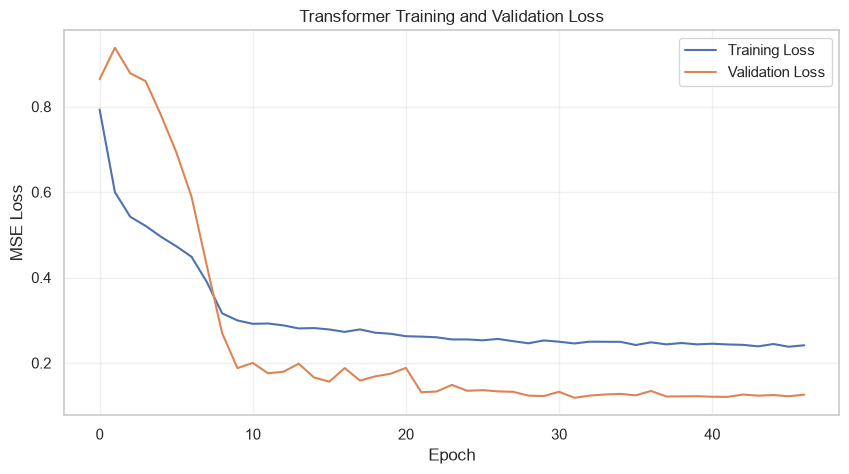

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_transformer.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_transformer.history["val_loss"],
    label="Validation Loss"
)

plt.title("Transformer Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [49]:
print("Target scaler:", scaler_y)

Target scaler: StandardScaler()


In [50]:
import numpy as np
import pandas as pd

# Transformer predictions
y_pred_scaled = transformer_model.predict(X_valid_scaled)

# Inverse transformation
y_pred = scaler_y.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).flatten()

y_actual = scaler_y.inverse_transform(
    np.array(y_valid_scaled).reshape(-1, 1)
).flatten()

# Sales quantity cannot be negative
y_pred = np.maximum(y_pred, 0)

print("Actual sales:", y_actual[:10])
print("Predicted sales:", y_pred[:10])

34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Actual sales: [5.70711026 5.53338949 5.62040087 5.86929691 5.6094718  5.5759491
 5.67332327 5.73334128 0.         0.        ]
Predicted sales: [5.4275184  5.387146   5.1511693  5.274227   5.3551307  5.3589334
 5.1944656  5.3806176  0.41512036 0.41512036]


In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

wape = (
    np.sum(np.abs(y_actual - y_pred))
    / np.sum(np.abs(y_actual))
) * 100

print("========== Transformer Evaluation ==========")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"WAPE : {wape:.2f}%")

========== Transformer Evaluation ==========
MAE  : 0.46
RMSE : 0.71
WAPE : 21.32%


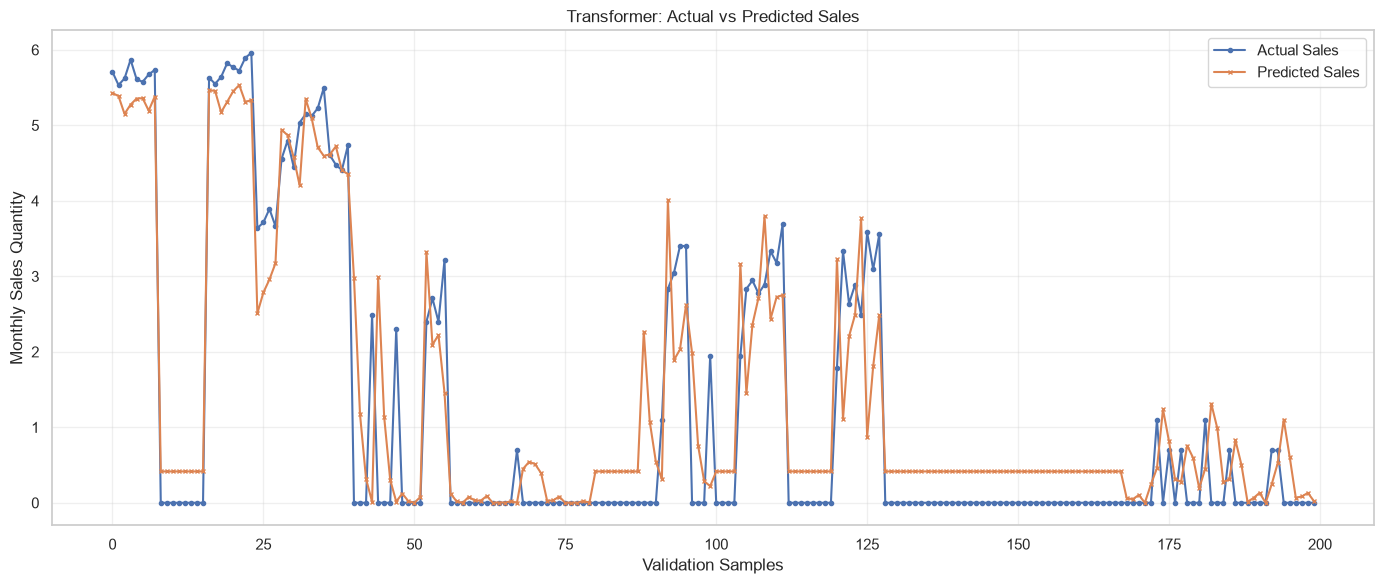

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_actual[:200],
    label="Actual Sales",
    marker="o",
    markersize=3
)

plt.plot(
    y_pred[:200],
    label="Predicted Sales",
    marker="x",
    markersize=3
)

plt.title("Transformer: Actual vs Predicted Sales")
plt.xlabel("Validation Samples")
plt.ylabel("Monthly Sales Quantity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Inverse StandardScaler
y_pred_log = scaler_y.inverse_transform(
    transformer_model.predict(X_valid_scaled)
).flatten()

y_actual_log = scaler_y.inverse_transform(
    np.array(y_valid_scaled).reshape(-1, 1)
).flatten()

# 2. Inverse log1p transformation
y_pred_original = np.expm1(y_pred_log)
y_actual_original = np.expm1(y_actual_log)

# Avoid negative predictions
y_pred_original = np.maximum(y_pred_original, 0)

# 3. Calculate metrics in original sales scale
mae_original = mean_absolute_error(
    y_actual_original, y_pred_original
)

rmse_original = np.sqrt(
    mean_squared_error(y_actual_original, y_pred_original)
)

wape_original = (
    np.sum(np.abs(y_actual_original - y_pred_original))
    / np.sum(np.abs(y_actual_original))
) * 100

print("===== Transformer: Original Sales Scale =====")
print(f"MAE  : {mae_original:.2f}")
print(f"RMSE : {rmse_original:.2f}")
print(f"WAPE : {wape_original:.2f}%")

print("\nActual sales:", y_actual_original[:10])
print("Predicted sales:", y_pred_original[:10])

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
===== Transformer: Original Sales Scale =====
MAE  : 14.61
RMSE : 32.29
WAPE : 35.67%

Actual sales: [300. 252. 275. 353. 272. 263. 290. 308.   0.   0.]
Predicted sales: [226.58377    217.57867    171.63324    194.23953    210.69164
 211.49818    179.27179    216.15636      0.51455307   0.51455307]


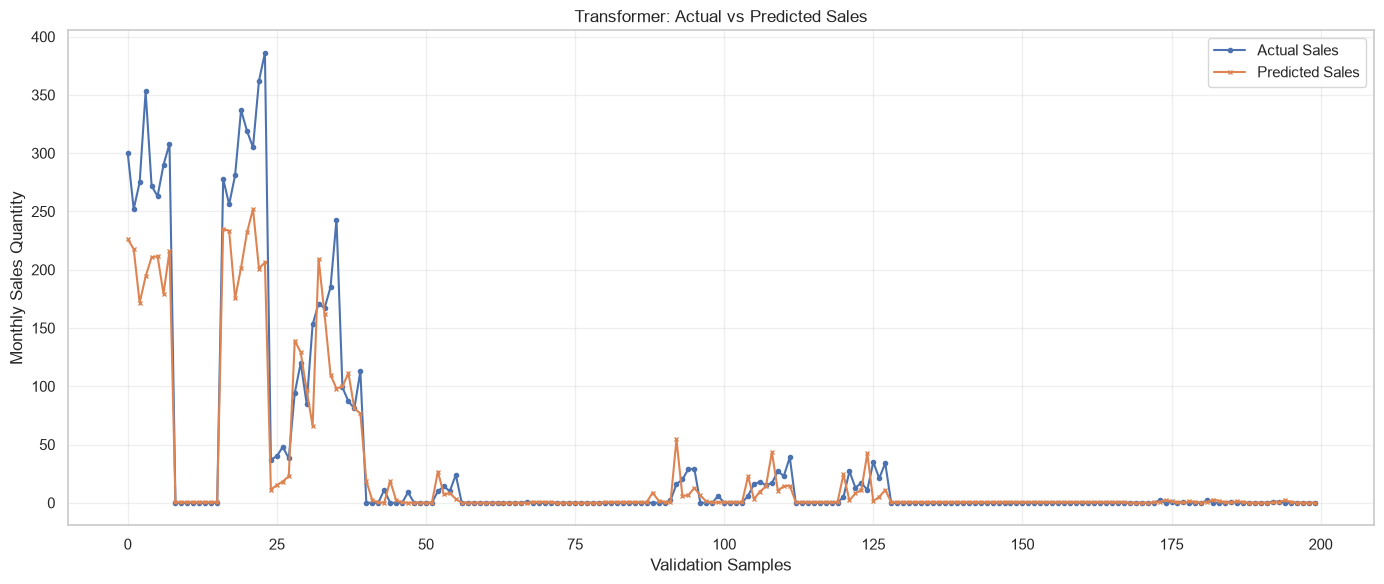

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_actual_original[:200],
    label="Actual Sales",
    marker="o",
    markersize=3
)

plt.plot(
    y_pred_original[:200],
    label="Predicted Sales",
    marker="x",
    markersize=3
)

plt.title("Transformer: Actual vs Predicted Sales")
plt.xlabel("Validation Samples")
plt.ylabel("Monthly Sales Quantity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()